**Tutorial Code by Amirhossein Ahrari YouTube:** https://www.youtube.com/@amirhosseinahrarigee

**Tutorial Video: PySTAC Tutorial-15: Sentinel-2 Crop Moisture Index Calculation in Python**

This code is part of a tutorial series on python eo programming techniques
presented on the Amirhossein Ahrari YouTube channel. You are free to use and modify
this code for academic and non-academic purposes. Don't forget to subscribe to
the Amirhossein Ahrari channel and follow the videos to support the instructor.

In [1]:
!pip install -q pystac-client
from pystac_client import Client

In [2]:
catalog = Client.open(
    'https://earth-search.aws.element84.com/v1'
)

In [3]:
for collection in catalog.get_collections():
  print(collection.id)

sentinel-2-pre-c1-l2a
cop-dem-glo-30
naip
cop-dem-glo-90
landsat-c2-l2
sentinel-2-l2a
sentinel-2-l1c
sentinel-2-c1-l2a
sentinel-1-grd


In [4]:
roi = [48.473671, 31.01833, 48.503015, 31.042759]

In [5]:
search = catalog.search(
    collections = ['sentinel-2-c1-l2a'],
    bbox = roi,
    datetime = '2025'
)

In [6]:
items = search.item_collection()

/usr/local/lib/python3.13/dist-packages/pystac/extensions/storage.py:724: UserWarning: Could not parse bucket/account from href. The following assets were not migrated: ['red', 'green', 'blue', 'visual', 'nir', 'swir22', 'rededge2', 'rededge3', 'rededge1', 'swir16', 'wvp', 'nir08', 'scl', 'aot', 'coastal', 'nir09', 'cloud', 'snow', 'preview', 'granule_metadata', 'tileinfo_metadata', 'product_metadata', 'thumbnail']
  warnings.warn(


In [7]:
len(items)

175

In [9]:
items[0].properties['proj:code']

'EPSG:32639'

In [11]:
items[0].assets.keys()

dict_keys(['red', 'green', 'blue', 'visual', 'nir', 'swir22', 'rededge2', 'rededge3', 'rededge1', 'swir16', 'wvp', 'nir08', 'scl', 'aot', 'coastal', 'nir09', 'cloud', 'snow', 'preview', 'granule_metadata', 'tileinfo_metadata', 'product_metadata', 'thumbnail'])

In [12]:
!pip install -q stackstac
from stackstac import stack

In [13]:
items_stack = stack(
    items,
    assets = ['nir','red','nir08','swir16','scl'],
    bounds_latlon = roi,
    resolution = 20,
    epsg = 32639
)

In [19]:
ds = (
    items_stack.to_dataset('band')
    .drop_dims('band')
    .reset_coords(drop = True)
    .drop_attrs()
)

In [20]:
mask = ds.scl.isin([0,1,3,8,9,10,11]).astype(int)
ds_mask = ds.drop('scl').where(mask == 0)

/tmp/ipykernel_1287/3988557067.py:2: DeprecationWarning: dropping variables using `drop` is deprecated; use drop_vars.
  ds_mask = ds.drop('scl').where(mask == 0)


In [21]:
red = ds_mask['red']
nir = ds_mask['nir']
ndvi = ( (nir - red) / (nir + red)).rename('ndvi')

In [22]:
nirn = ds_mask['nir08']
swir = ds_mask['swir16']
ndmi = ( (nirn - swir) / (nirn + swir)).rename('ndmi')

In [23]:
import xarray as xr

In [24]:
ds_merge = xr.merge([ndvi, ndmi])

In [26]:
ds_monthly = ds_merge.resample(time = 'M').max('time')

/usr/local/lib/python3.13/dist-packages/xarray/groupers.py:530: FutureWarning: 'M' is deprecated and will be removed in a future version, please use 'ME' instead.
  self.index_grouper = pd.Grouper(


In [27]:
ds_monthly

<xarray.Dataset> Size: 4MB
Dimensions:  (time: 12, y: 140, x: 144)
Coordinates:
  * time     (time) datetime64[ns] 96B 2025-01-31 2025-02-28 ... 2025-12-31
  * y        (y) float64 1kB 3.437e+06 3.437e+06 ... 3.434e+06 3.434e+06
  * x        (x) float64 1kB 2.588e+05 2.588e+05 ... 2.617e+05 2.617e+05
Data variables:
    ndvi     (time, y, x) float64 2MB dask.array<chunksize=(1, 140, 144), meta=np.ndarray>
    ndmi     (time, y, x) float64 2MB dask.array<chunksize=(1, 140, 144), meta=np.ndarray>

In [28]:
from dask.diagnostics import ProgressBar

In [30]:
import warnings
warnings.filterwarnings('ignore', category = RuntimeWarning)
import logging
logging.getLogger().setLevel(logging.ERROR)

In [31]:
with ProgressBar():
  ds_monthly = ds_monthly.compute()

[########################################] | 100% Completed | 166.75 s


In [32]:
ds_mean = ds_monthly.mean(dim = 'time')

In [34]:
import matplotlib.pyplot as plt

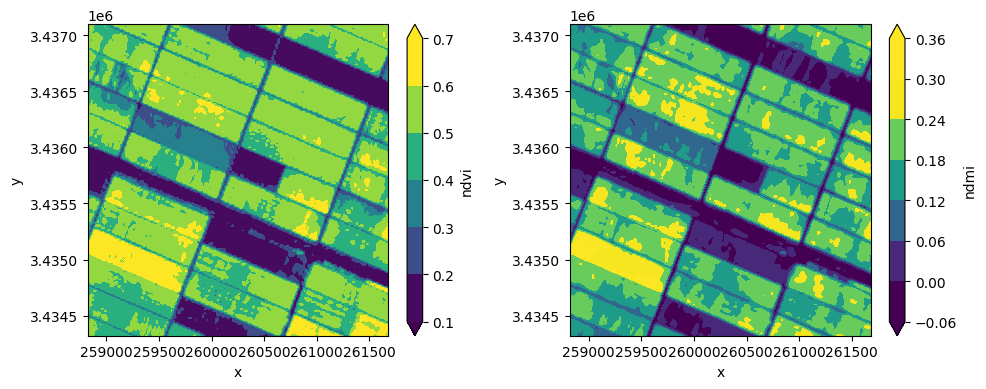

In [38]:
fig, ax = plt.subplots(1, 2, figsize = (10,4))

ds_mean.ndvi.plot.contourf(ax = ax[0], robust =True)
ds_mean.ndmi.plot.contourf(ax = ax[1], robust = True, vmin = 0)

plt.tight_layout()

In [39]:
ds_std = ds_monthly.std(dim = 'time')

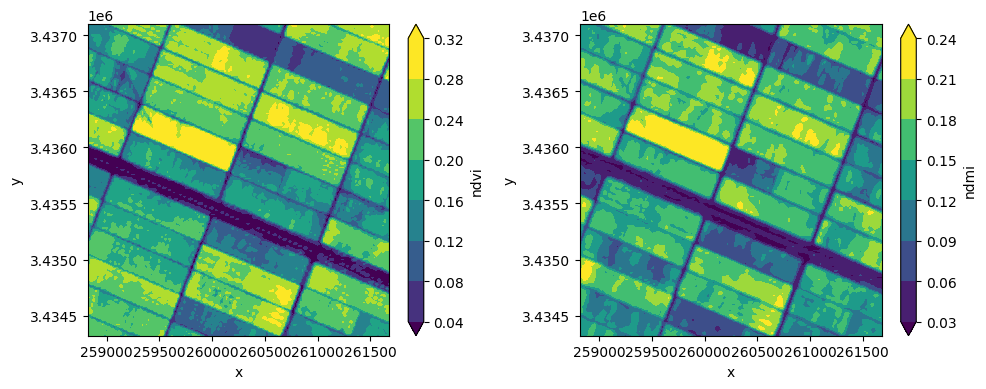

In [40]:
fig, ax = plt.subplots(1, 2, figsize = (10,4))

ds_std.ndvi.plot.contourf(ax = ax[0], robust = True)
ds_std.ndmi.plot.contourf(ax = ax[1], robust = True)

plt.tight_layout()